In [1]:
import numpy as np
from helpers.model import *
from helpers.plotting import *

In [2]:
a_c = 0.125 # m/s^2

x0_c = 2
y0_c = 0
z0_c = 1

vx0_c = 0
vy0_c = 0.5
vz0_c = 0

phi0_c = -np.atan2(a_c, g)
theta0_c = 0
psi0_c = np.pi/2

omega1_c = 0
omega2_c = 0.25*np.sin(phi0_c)
omega3_c = 0.25*np.cos(phi0_c)

T_c = m*np.sqrt(g**2 + a_c**2)
M1_c = (I3 - I2)*omega2_c*omega3_c

T0_c = np.array([T_c/4, T_c/4 + M1_c/(2*l), T_c/4, T_c/4 - M1_c/(2*l)])
Omega0_c = np.sqrt(T0_c/k_T)

E0_c = 0

u_c = k_Q * Omega0_c**2 # N m

f_circle = lambda r, t : state_dot(r, t, u_c)

r0_c = np.array([x0_c, y0_c, z0_c, vx0_c, vy0_c, vz0_c, phi0_c, theta0_c, psi0_c, omega1_c, omega2_c, omega3_c, Omega0_c[0], Omega0_c[1], Omega0_c[2], Omega0_c[3], E0_c])

r_circle, times_c = forward_euler(f_circle, r0_c, 60, 0.001)

x_c_desired = 2*np.cos(0.25*times_c)
y_c_desired = 2*np.sin(0.25*times_c)

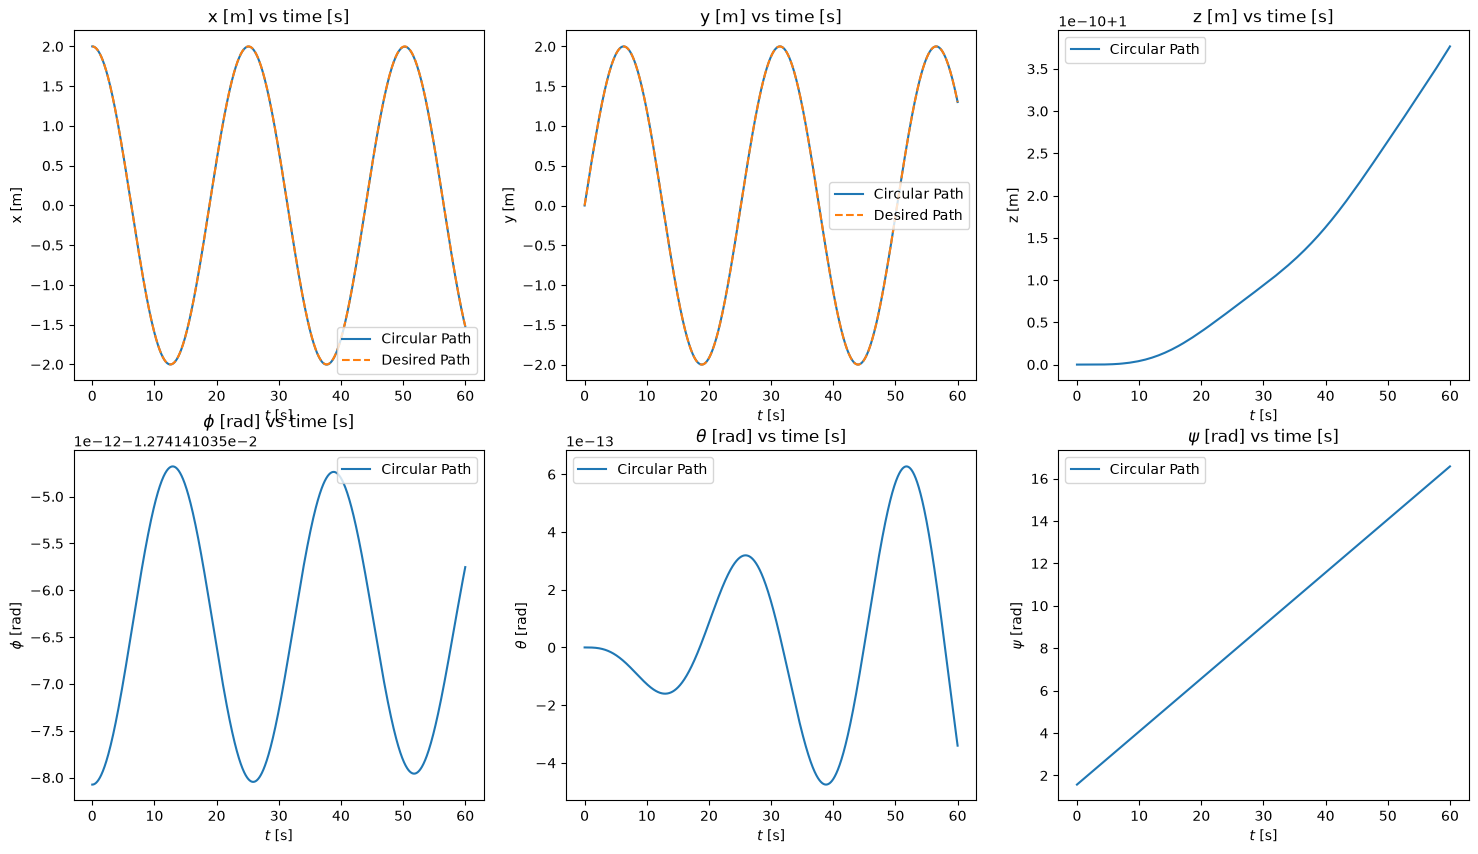

In [3]:
fig = plotDegreesOfFreedom(times_c, r_circle, 'Circular Path')
axes = fig.axes

axes[0].plot(times_c, x_c_desired, label='Desired Path', ls='--')
axes[0].legend()
axes[1].plot(times_c, y_c_desired, label='Desired Path', ls='--')
axes[1].legend()

In [4]:
max_x_c_error = np.max(np.abs(r_circle[:,0] - x_c_desired))
max_y_c_error = np.max(np.abs(r_circle[:,0] - y_c_desired))
E_circle_f = r_circle[-1][16]

print(f'Maximum error x: {max_x_c_error}')
print(f'Maximum error y: {max_x_c_error}')
print(f'Energy used: {E_circle_f} J')

Maximum error x: 0.003424778617650892
Maximum error y: 0.003424778617650892
Energy used: 8792.45749467119 J


In [5]:
fig.savefig("Figures/PG2-DegreesOfFreedom.pdf", format="pdf", bbox_inches="tight")